## Import Libraries

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

## Configuration
Change only this cell when reusing the notebook for another pose.

In [2]:
POSE_NAME = "Ardha Chandrasana"
MODEL_FILENAME = "ardha_chandrasana_rf.pkl"

FEATURES = [
    "left_knee",
    "right_knee",
    "left_hip",
    "right_hip",
    "left_shoulder",
    "right_shoulder"
]

TARGET_COL = "target"
RANDOM_STATE = 42

## Load and Merge Datasets (Train / Val / Test)
Loads the pre-split correct/incorrect CSVs, merges them, and shuffles rows.

In [3]:
def load_and_merge(split_name):
    correct_path = f"{split_name}/correct_{split_name}.csv"
    incorrect_path = f"{split_name}/incorrect_{split_name}.csv"

    if not os.path.exists(correct_path) or not os.path.exists(incorrect_path):
        raise FileNotFoundError(
            f"Missing files for split '{split_name}'. "
            f"Expected: {correct_path} and {incorrect_path}"
        )

    correct_df = pd.read_csv(correct_path)
    incorrect_df = pd.read_csv(incorrect_path)

    df = pd.concat([correct_df, incorrect_df], ignore_index=True)
    df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    return df

train_df = load_and_merge("train")
val_df   = load_and_merge("val")
test_df  = load_and_merge("test")

print("Train Shape :", train_df.shape)
print("Val Shape   :", val_df.shape)
print("Test Shape  :", test_df.shape)

Train Shape : (3152, 10)
Val Shape   : (676, 10)
Test Shape  : (676, 10)


## Sanity Checks

In [4]:
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    missing = df[FEATURES + [TARGET_COL]].isnull().sum().sum()
    print(f"{name} missing values: {missing}")
    assert missing == 0, f"{name} split has missing values in required columns"

print("\nClass Distribution")
print("Train:\n", train_df[TARGET_COL].value_counts())
print("\nVal:\n", val_df[TARGET_COL].value_counts())
print("\nTest:\n", test_df[TARGET_COL].value_counts())

Train missing values: 0
Val missing values: 0
Test missing values: 0

Class Distribution
Train:
 target
0    2248
1     904
Name: count, dtype: int64

Val:
 target
0    482
1    194
Name: count, dtype: int64

Test:
 target
0    482
1    194
Name: count, dtype: int64


## Feature / Target Split

In [5]:
X_train, y_train = train_df[FEATURES], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET_COL]

## Train Random Forest

In [6]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

rf.fit(X_train, y_train)
print("Model Trained Successfully")

Model Trained Successfully


## Train vs Validation Accuracy (Overfitting Check)

In [7]:
train_pred = rf.predict(X_train)
val_pred   = rf.predict(X_val)

train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy   = accuracy_score(y_val, val_pred)

print(f"Train Accuracy      : {train_accuracy*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy*100:.2f}%")
print(f"Gap (Train - Val)   : {(train_accuracy - val_accuracy)*100:.2f}%")

if (train_accuracy - val_accuracy) > 0.10:
    print("Warning: large train-val gap, model may be overfitting")

print("\nValidation Classification Report")
print(classification_report(y_val, val_pred, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 98.52%
Gap (Train - Val)   : 1.48%

Validation Classification Report
              precision    recall  f1-score   support

   Incorrect       1.00      0.98      0.99       482
     Correct       0.96      0.99      0.97       194

    accuracy                           0.99       676
   macro avg       0.98      0.99      0.98       676
weighted avg       0.99      0.99      0.99       676



## Test Set Evaluation

In [8]:
test_pred = rf.predict(X_test)

test_accuracy  = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred)
test_recall    = recall_score(y_test, test_pred)
test_f1        = f1_score(y_test, test_pred)

print(f"Test Accuracy  : {test_accuracy*100:.2f}%")
print(f"Test Precision : {test_precision*100:.2f}%")
print(f"Test Recall    : {test_recall*100:.2f}%")
print(f"Test F1 Score  : {test_f1*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test, test_pred, target_names=["Incorrect", "Correct"]))

Test Accuracy  : 97.19%
Test Precision : 97.81%
Test Recall    : 92.27%
Test F1 Score  : 94.96%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       0.97      0.99      0.98       482
     Correct       0.98      0.92      0.95       194

    accuracy                           0.97       676
   macro avg       0.97      0.96      0.97       676
weighted avg       0.97      0.97      0.97       676



Average confidence : 95.69%
Minimum confidence : 50.00%


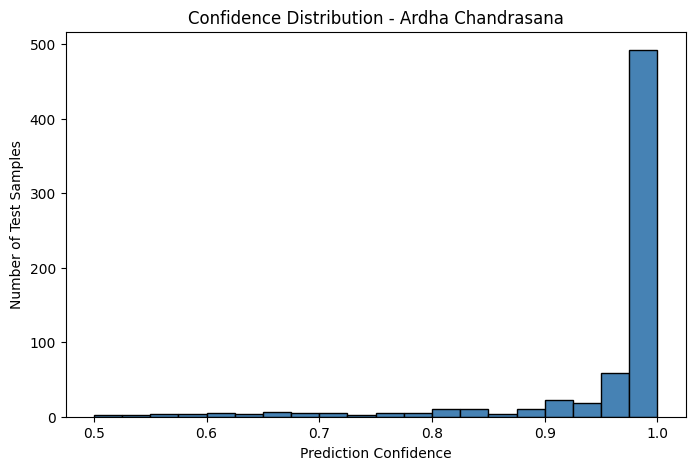

In [9]:
test_probs = rf.predict_proba(X_test)
test_confidence = test_probs.max(axis=1)  # confidence in whichever class was predicted

print(f"Average confidence : {test_confidence.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME}")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Confusion Matrix

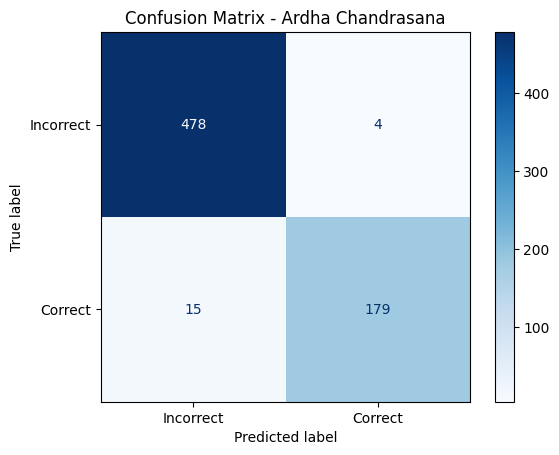

In [10]:
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Incorrect", "Correct"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME}")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature Importance

          Feature  Importance
0      right_knee    0.190071
1  right_shoulder    0.180046
2   left_shoulder    0.174942
3        left_hip    0.174140
4       right_hip    0.155633
5       left_knee    0.125168


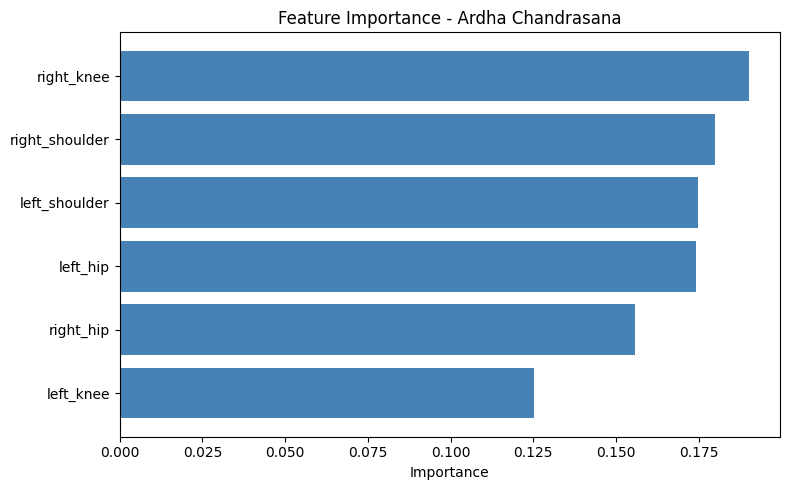

In [11]:
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Save Model and Metadata

In [12]:
joblib.dump(rf, MODEL_FILENAME)

metadata = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy, 4),
    "val_accuracy": round(val_accuracy, 4),
    "test_accuracy": round(test_accuracy, 4),
    "test_precision": round(test_precision, 4),
    "test_recall": round(test_recall, 4),
    "test_f1_score": round(test_f1, 4),
    "n_estimators": rf.n_estimators,
    "random_state": rf.random_state
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")

Model saved as ardha_chandrasana_rf.pkl
Metadata saved as ardha_chandrasana_rf_metadata.json


## Test with One Sample

In [13]:
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)[0]
probabilities = rf.predict_proba(sample)[0]
confidence = probabilities[prediction]

print("Prediction :", prediction)
print(f"{'Correct' if prediction == 1 else 'Incorrect'} {POSE_NAME}")
print(f"Confidence : {confidence*100:.2f}%")
print(f"  P(Incorrect) = {probabilities[0]*100:.2f}%")
print(f"  P(Correct)   = {probabilities[1]*100:.2f}%")

Prediction : 0
Incorrect Ardha Chandrasana
Confidence : 100.00%
  P(Incorrect) = 100.00%
  P(Correct)   = 0.00%


## Data Cleaning Fix - Standing Pose Contamination

Real-time testing revealed the model above classifies plain standing (arms down, no lean, no lift) as a **Correct** Half Moon pose. Checking the raw training data confirmed why: 41.1% of "Correct" examples matched a plain-standing angle pattern (straight knees/hips, arms down) - likely prep/transition frames from the source videos that were mislabeled as Correct during Phase 2.

**Fix (two parts):**
1. Remove the standing-like contaminated rows from the raw Correct-class data.
2. Add synthetic standing-pose examples explicitly labeled Incorrect - removing contaminated rows alone left that region of the data almost empty, so the model kept extrapolating toward Correct. Since we know with certainty that plain standing is not a valid Half Moon pose, this encodes real domain knowledge rather than a guess.

**This section retrains and overwrites `ardha_chandrasana_rf.pkl` / `ardha_chandrasana_rf_metadata.json` with the corrected model. The evaluation above (pre-fix) is kept for comparison; the results in this section reflect the final saved model.**

In [14]:
from sklearn.model_selection import train_test_split

# Raw (pre-split) source files
RAW_CORRECT_FILE = "../CSV/correct_ardha_chandrasana (1).csv"
RAW_INCORRECT_FILE = "../CSV/incorrect_ardha_chandrasana (1).csv"

# Standing-contamination filter thresholds
STANDING_KNEE_HIP_MIN = 165
STANDING_SHOULDER_MAX = 40

def is_standing_like(df):
    """Rows matching plain-standing geometry: straight knees/hips, arms down."""
    return (
        (df["left_knee"] > STANDING_KNEE_HIP_MIN) &
        (df["right_knee"] > STANDING_KNEE_HIP_MIN) &
        (df["left_hip"] > STANDING_KNEE_HIP_MIN) &
        (df["right_hip"] > STANDING_KNEE_HIP_MIN) &
        (df["left_shoulder"] < STANDING_SHOULDER_MAX) &
        (df["right_shoulder"] < STANDING_SHOULDER_MAX)
    )

raw_correct = pd.read_csv(RAW_CORRECT_FILE)
raw_incorrect = pd.read_csv(RAW_INCORRECT_FILE)

print(f"Before cleaning -> Correct: {raw_correct.shape} | Incorrect: {raw_incorrect.shape}")

standing_mask = is_standing_like(raw_correct)
removed_count = standing_mask.sum()
raw_correct_clean = raw_correct[~standing_mask].reset_index(drop=True)

print(f"Removed {removed_count} standing-like rows from 'Correct' class "
      f"({removed_count/len(raw_correct)*100:.1f}% of original Correct data)")
print(f"After cleaning  -> Correct: {raw_correct_clean.shape} | Incorrect: {raw_incorrect.shape}")

raw_correct_clean = raw_correct_clean.drop_duplicates(subset=FEATURES).reset_index(drop=True)
raw_incorrect_clean = raw_incorrect.drop_duplicates(subset=FEATURES).reset_index(drop=True)

print(f"After dedup     -> Correct: {raw_correct_clean.shape} | Incorrect: {raw_incorrect_clean.shape}")

Before cleaning -> Correct: (2414, 10) | Incorrect: (2612, 10)
Removed 993 standing-like rows from 'Correct' class (41.1% of original Correct data)
After cleaning  -> Correct: (1421, 10) | Incorrect: (2612, 10)
After dedup     -> Correct: (1421, 10) | Incorrect: (2612, 10)


### Add Synthetic Standing Examples to Incorrect Class
Encodes the known fact that plain standing is not Ardha Chandrasana, so the model has real examples to learn this region as Incorrect.

In [15]:
rng = np.random.default_rng(RANDOM_STATE)
N_SYNTHETIC = 400

synthetic_standing = pd.DataFrame({
    "left_knee":  rng.normal(177, 2.5, N_SYNTHETIC).clip(165, 180),
    "right_knee": rng.normal(177, 2.5, N_SYNTHETIC).clip(165, 180),
    "left_hip":   rng.normal(177, 2.5, N_SYNTHETIC).clip(165, 180),
    "right_hip":  rng.normal(177, 2.5, N_SYNTHETIC).clip(165, 180),
    "left_shoulder":  rng.normal(15, 8, N_SYNTHETIC).clip(0, 39),
    "right_shoulder": rng.normal(15, 8, N_SYNTHETIC).clip(0, 39),
})
synthetic_standing[TARGET_COL] = 0

print(f"Added {N_SYNTHETIC} synthetic standing-pose examples to Incorrect class.")

raw_incorrect_clean = pd.concat([raw_incorrect_clean, synthetic_standing], ignore_index=True)
print(f"Incorrect class after synthetic addition: {raw_incorrect_clean.shape}")

Added 400 synthetic standing-pose examples to Incorrect class.
Incorrect class after synthetic addition: (3012, 10)


### Rebuild Clean Train/Val/Test Split

In [16]:
def split_70_15_15(df, random_state=RANDOM_STATE):
    train, temp = train_test_split(df, test_size=0.30, random_state=random_state)
    val, test = train_test_split(temp, test_size=0.50, random_state=random_state)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

correct_train_c, correct_val_c, correct_test_c = split_70_15_15(raw_correct_clean)
incorrect_train_c, incorrect_val_c, incorrect_test_c = split_70_15_15(raw_incorrect_clean)

for split in ["train", "val", "test"]:
    os.makedirs(split, exist_ok=True)

correct_train_c.to_csv("train/correct_train.csv", index=False)
incorrect_train_c.to_csv("train/incorrect_train.csv", index=False)
correct_val_c.to_csv("val/correct_val.csv", index=False)
incorrect_val_c.to_csv("val/incorrect_val.csv", index=False)
correct_test_c.to_csv("test/correct_test.csv", index=False)
incorrect_test_c.to_csv("test/incorrect_test.csv", index=False)

print("New split sizes:")
print("Train:", len(correct_train_c) + len(incorrect_train_c))
print("Val  :", len(correct_val_c) + len(incorrect_val_c))
print("Test :", len(correct_test_c) + len(incorrect_test_c))

New split sizes:
Train: 3102
Val  : 665
Test : 666


### Verify No Leakage

In [17]:
def load_merge_clean(split_name):
    c = pd.read_csv(f"{split_name}/correct_{split_name}.csv")
    i = pd.read_csv(f"{split_name}/incorrect_{split_name}.csv")
    return pd.concat([c, i], ignore_index=True)

train_df_c = load_merge_clean("train")
val_df_c = load_merge_clean("val")
test_df_c = load_merge_clean("test")

_train_set_c = set(map(tuple, train_df_c[FEATURES].round(4).values))
_val_set_c   = set(map(tuple, val_df_c[FEATURES].round(4).values))
_test_set_c  = set(map(tuple, test_df_c[FEATURES].round(4).values))

overlap_tv = len(_train_set_c & _val_set_c)
overlap_tt = len(_train_set_c & _test_set_c)
overlap_vt = len(_val_set_c & _test_set_c)

print("Train ∩ Val overlap :", overlap_tv)
print("Train ∩ Test overlap:", overlap_tt)
print("Val ∩ Test overlap  :", overlap_vt)

assert overlap_tv == 0, "Leakage between train and val!"
assert overlap_tt == 0, "Leakage between train and test!"
assert overlap_vt == 0, "Leakage between val and test!"
print("No leakage. Safe to train.")

Train ∩ Val overlap : 0
Train ∩ Test overlap: 0
Val ∩ Test overlap  : 0
No leakage. Safe to train.


### Retrain on Cleaned Data

In [18]:
X_train_c, y_train_c = train_df_c[FEATURES], train_df_c[TARGET_COL]
X_val_c,   y_val_c   = val_df_c[FEATURES],   val_df_c[TARGET_COL]
X_test_c,  y_test_c  = test_df_c[FEATURES],  test_df_c[TARGET_COL]

rf_clean = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_clean.fit(X_train_c, y_train_c)
print("Model trained on cleaned data.")

Model trained on cleaned data.


### Evaluate Cleaned Model

In [19]:
train_pred_c = rf_clean.predict(X_train_c)
val_pred_c   = rf_clean.predict(X_val_c)
test_pred_c  = rf_clean.predict(X_test_c)

train_accuracy_c = accuracy_score(y_train_c, train_pred_c)
val_accuracy_c   = accuracy_score(y_val_c, val_pred_c)
test_accuracy_c  = accuracy_score(y_test_c, test_pred_c)
test_precision_c = precision_score(y_test_c, test_pred_c)
test_recall_c    = recall_score(y_test_c, test_pred_c)
test_f1_c        = f1_score(y_test_c, test_pred_c)

print(f"Train Accuracy      : {train_accuracy_c*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy_c*100:.2f}%")
print(f"Test Accuracy       : {test_accuracy_c*100:.2f}%")
print(f"Test Precision      : {test_precision_c*100:.2f}%")
print(f"Test Recall         : {test_recall_c*100:.2f}%")
print(f"Test F1             : {test_f1_c*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test_c, test_pred_c, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 96.39%
Test Accuracy       : 96.70%
Test Precision      : 95.71%
Test Recall         : 93.93%
Test F1             : 94.81%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       0.97      0.98      0.98       452
     Correct       0.96      0.94      0.95       214

    accuracy                           0.97       666
   macro avg       0.96      0.96      0.96       666
weighted avg       0.97      0.97      0.97       666



### Standing-Pose Sanity Check
Directly tests whether the retrained model now correctly rejects plain standing as Incorrect.

In [20]:
plain_standing = pd.DataFrame([{
    "left_knee": 178.0, "right_knee": 178.0,
    "left_hip": 178.0, "right_hip": 178.0,
    "left_shoulder": 12.0, "right_shoulder": 11.0
}])[FEATURES]

standing_pred = rf_clean.predict(plain_standing)[0]
standing_proba = rf_clean.predict_proba(plain_standing)[0]

print("Standing-pose sanity check (should predict Incorrect):")
print(f"  Prediction: {'Correct' if standing_pred == 1 else 'Incorrect'}")
print(f"  P(Incorrect) = {standing_proba[0]*100:.2f}%  P(Correct) = {standing_proba[1]*100:.2f}%")
if standing_pred == 1:
    print("  WARNING: Model still classifies plain standing as Correct.")
else:
    print("  Fix confirmed: plain standing is now correctly rejected.")

Standing-pose sanity check (should predict Incorrect):
  Prediction: Incorrect
  P(Incorrect) = 98.00%  P(Correct) = 2.00%
  Fix confirmed: plain standing is now correctly rejected.


### Confusion Matrix (Cleaned Model)

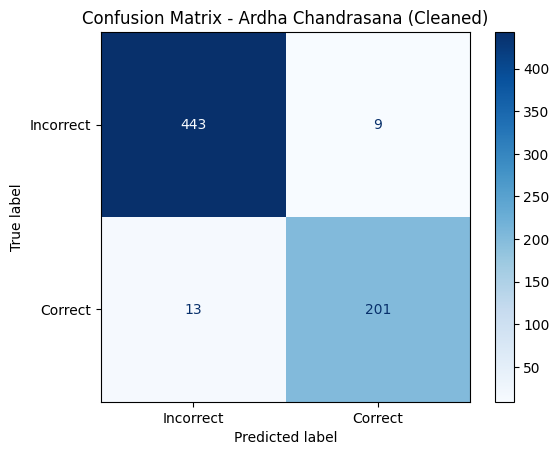

In [21]:
cm_c = confusion_matrix(y_test_c, test_pred_c)

disp_c = ConfusionMatrixDisplay(
    confusion_matrix=cm_c,
    display_labels=["Incorrect", "Correct"]
)

disp_c.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME} (Cleaned)")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower().replace(' ', '_')}_cleaned.png", dpi=150, bbox_inches="tight")
plt.show()

### Feature Importance (Cleaned Model)

          Feature  Importance
0      right_knee    0.206466
1  right_shoulder    0.179047
2   left_shoulder    0.174589
3       right_hip    0.158438
4        left_hip    0.150043
5       left_knee    0.131417


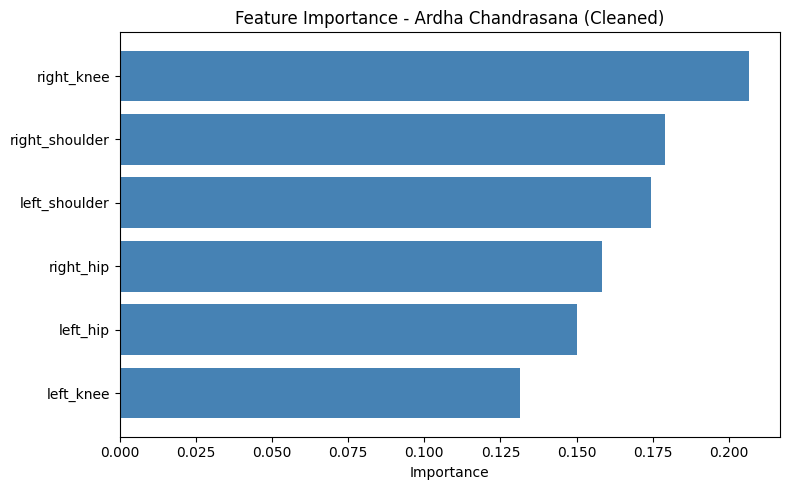

In [22]:
importance_df_c = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_clean.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df_c)

plt.figure(figsize=(8, 5))
plt.barh(importance_df_c["Feature"], importance_df_c["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME} (Cleaned)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower().replace(' ', '_')}_cleaned.png", dpi=150)
plt.show()

### Confidence (Cleaned Model)

Average confidence : 94.48%
Minimum confidence : 50.00%


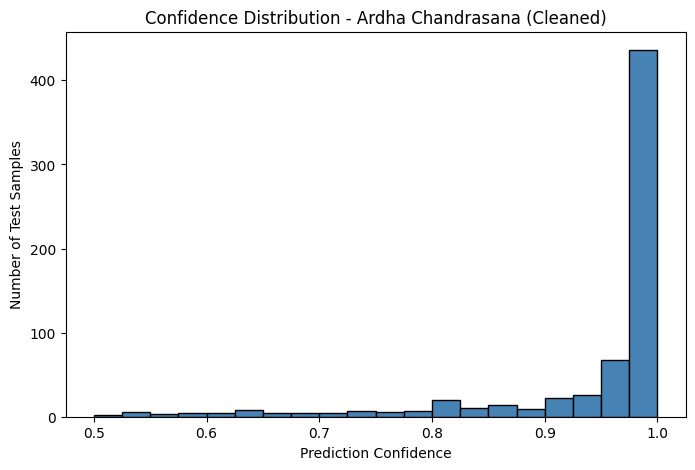

In [23]:
test_probs_c = rf_clean.predict_proba(X_test_c)
test_confidence_c = test_probs_c.max(axis=1)

print(f"Average confidence : {test_confidence_c.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence_c.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence_c, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME} (Cleaned)")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower().replace(' ', '_')}_cleaned.png", dpi=150)
plt.show()

### Save Final Model and Metadata
**This overwrites `ardha_chandrasana_rf.pkl` / `ardha_chandrasana_rf_metadata.json` with the cleaned model. This is the final Ardha Chandrasana model going forward.**

In [24]:
joblib.dump(rf_clean, MODEL_FILENAME)

metadata_c = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy_c, 4),
    "val_accuracy": round(val_accuracy_c, 4),
    "test_accuracy": round(test_accuracy_c, 4),
    "test_precision": round(test_precision_c, 4),
    "test_recall": round(test_recall_c, 4),
    "test_f1_score": round(test_f1_c, 4),
    "n_estimators": rf_clean.n_estimators,
    "random_state": rf_clean.random_state,
    "data_cleaned": True,
    "note": f"Removed {removed_count} standing-pose-contaminated rows ({removed_count/len(raw_correct)*100:.1f}% of original Correct class) mislabeled as Correct, and added {N_SYNTHETIC} synthetic standing examples to Incorrect class. Fixes plain-standing being misclassified as a correct Half Moon pose."
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata_c, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")
print("This is the final Ardha Chandrasana model - correctly rejects plain standing.")

Model saved as ardha_chandrasana_rf.pkl
Metadata saved as ardha_chandrasana_rf_metadata.json
This is the final Ardha Chandrasana model - correctly rejects plain standing.


## Data Cleaning Fix v2 - Standing Pose Contamination (Arms Raised Gap)

The v1 fix above only removed standing-contaminated rows with arms DOWN (shoulder<40), which missed rows where the person stood straight but had arms RAISED (shoulder>100) - still not a real Half Moon pose (no hip bend, no leg lift), but not caught by v1's filter. Confirmed via live testing: standing with arms raised overhead, and a near-boundary standing case, still showed "Correct".

**Root insight:** genuine Ardha Chandrasana ALWAYS requires a bent hip (leaning + one leg lifted). Straight hips (>160 deg) should NEVER be Correct, regardless of arm position. This v2 fix filters and synthesizes negatives based on hip/knee straightness ALONE (not combined with a low-shoulder requirement), with a wider 160 deg margin so near-boundary readings don't slip through.

**This section retrains and overwrites `ardha_chandrasana_rf.pkl` / `ardha_chandrasana_rf_metadata.json` with the final corrected model, superseding v1.**

In [25]:
STRAIGHT_KNEE_HIP_MIN_V2 = 160  # wider margin than v1's 165

def is_straight_pose_v2(df):
    """Rows where hips AND knees are straight - not a real Half Moon regardless of arms."""
    return (
        (df["left_knee"] > STRAIGHT_KNEE_HIP_MIN_V2) &
        (df["right_knee"] > STRAIGHT_KNEE_HIP_MIN_V2) &
        (df["left_hip"] > STRAIGHT_KNEE_HIP_MIN_V2) &
        (df["right_hip"] > STRAIGHT_KNEE_HIP_MIN_V2)
    )

raw_correct_v2 = pd.read_csv(RAW_CORRECT_FILE)
raw_incorrect_v2 = pd.read_csv(RAW_INCORRECT_FILE)

print(f"Before cleaning -> Correct: {raw_correct_v2.shape} | Incorrect: {raw_incorrect_v2.shape}")

straight_mask_v2 = is_straight_pose_v2(raw_correct_v2)
removed_count_v2 = straight_mask_v2.sum()
raw_correct_clean_v2 = raw_correct_v2[~straight_mask_v2].reset_index(drop=True)

print(f"Removed {removed_count_v2} straight-hip/knee rows from 'Correct' class "
      f"({removed_count_v2/len(raw_correct_v2)*100:.1f}% of original Correct data)")

raw_correct_clean_v2 = raw_correct_clean_v2.drop_duplicates(subset=FEATURES).reset_index(drop=True)
raw_incorrect_clean_v2 = raw_incorrect_v2.drop_duplicates(subset=FEATURES).reset_index(drop=True)
print(f"After dedup -> Correct: {raw_correct_clean_v2.shape} | Incorrect: {raw_incorrect_clean_v2.shape}")

Before cleaning -> Correct: (2414, 10) | Incorrect: (2612, 10)
Removed 1122 straight-hip/knee rows from 'Correct' class (46.5% of original Correct data)
After dedup -> Correct: (1292, 10) | Incorrect: (2612, 10)


### Add Synthetic Negatives - Full Shoulder Range
Covers BOTH arms-down AND arms-up standing variants (v1 only covered arms-down).

In [26]:
rng_v2 = np.random.default_rng(RANDOM_STATE)
N_SYNTHETIC_V2 = 600

synthetic_straight_v2 = pd.DataFrame({
    "left_knee":  rng_v2.normal(177, 3, N_SYNTHETIC_V2).clip(160, 180),
    "right_knee": rng_v2.normal(177, 3, N_SYNTHETIC_V2).clip(160, 180),
    "left_hip":   rng_v2.normal(177, 3, N_SYNTHETIC_V2).clip(160, 180),
    "right_hip":  rng_v2.normal(177, 3, N_SYNTHETIC_V2).clip(160, 180),
    "left_shoulder":  rng_v2.uniform(0, 180, N_SYNTHETIC_V2),
    "right_shoulder": rng_v2.uniform(0, 180, N_SYNTHETIC_V2),
})
synthetic_straight_v2[TARGET_COL] = 0

print(f"Added {N_SYNTHETIC_V2} synthetic straight-hip/knee examples (full shoulder range) to Incorrect class.")

raw_incorrect_clean_v2 = pd.concat([raw_incorrect_clean_v2, synthetic_straight_v2], ignore_index=True)
print(f"Incorrect class after synthetic addition: {raw_incorrect_clean_v2.shape}")

Added 600 synthetic straight-hip/knee examples (full shoulder range) to Incorrect class.
Incorrect class after synthetic addition: (3212, 10)


### Rebuild Clean Train/Val/Test Split (v2)

In [27]:
from sklearn.model_selection import train_test_split

def split_70_15_15_v2(df, random_state=RANDOM_STATE):
    train, temp = train_test_split(df, test_size=0.30, random_state=random_state)
    val, test = train_test_split(temp, test_size=0.50, random_state=random_state)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

correct_train_v2, correct_val_v2, correct_test_v2 = split_70_15_15_v2(raw_correct_clean_v2)
incorrect_train_v2, incorrect_val_v2, incorrect_test_v2 = split_70_15_15_v2(raw_incorrect_clean_v2)

for split in ["train", "val", "test"]:
    os.makedirs(split, exist_ok=True)

correct_train_v2.to_csv("train/correct_train.csv", index=False)
incorrect_train_v2.to_csv("train/incorrect_train.csv", index=False)
correct_val_v2.to_csv("val/correct_val.csv", index=False)
incorrect_val_v2.to_csv("val/incorrect_val.csv", index=False)
correct_test_v2.to_csv("test/correct_test.csv", index=False)
incorrect_test_v2.to_csv("test/incorrect_test.csv", index=False)

print("New split sizes:")
print("Train:", len(correct_train_v2) + len(incorrect_train_v2))
print("Val  :", len(correct_val_v2) + len(incorrect_val_v2))
print("Test :", len(correct_test_v2) + len(incorrect_test_v2))

New split sizes:
Train: 3152
Val  : 676
Test : 676


### Verify No Leakage (v2)

In [28]:
def load_merge_v2(split_name):
    c = pd.read_csv(f"{split_name}/correct_{split_name}.csv")
    i = pd.read_csv(f"{split_name}/incorrect_{split_name}.csv")
    return pd.concat([c, i], ignore_index=True)

train_df_v2 = load_merge_v2("train")
val_df_v2 = load_merge_v2("val")
test_df_v2 = load_merge_v2("test")

_train_set_v2 = set(map(tuple, train_df_v2[FEATURES].round(4).values))
_val_set_v2   = set(map(tuple, val_df_v2[FEATURES].round(4).values))
_test_set_v2  = set(map(tuple, test_df_v2[FEATURES].round(4).values))

overlap_tv2 = len(_train_set_v2 & _val_set_v2)
overlap_tt2 = len(_train_set_v2 & _test_set_v2)
overlap_vt2 = len(_val_set_v2 & _test_set_v2)

print("Train ∩ Val overlap :", overlap_tv2)
print("Train ∩ Test overlap:", overlap_tt2)
print("Val ∩ Test overlap  :", overlap_vt2)

assert overlap_tv2 == 0
assert overlap_tt2 == 0
assert overlap_vt2 == 0
print("No leakage. Safe to train.")

Train ∩ Val overlap : 0
Train ∩ Test overlap: 0
Val ∩ Test overlap  : 0
No leakage. Safe to train.


### Retrain on v2 Cleaned Data

In [29]:
X_train_v2, y_train_v2 = train_df_v2[FEATURES], train_df_v2[TARGET_COL]
X_val_v2,   y_val_v2   = val_df_v2[FEATURES],   val_df_v2[TARGET_COL]
X_test_v2,  y_test_v2  = test_df_v2[FEATURES],  test_df_v2[TARGET_COL]

rf_v2 = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
rf_v2.fit(X_train_v2, y_train_v2)
print("Model trained on v2 cleaned + widened-negative data.")

Model trained on v2 cleaned + widened-negative data.


### Evaluate v2 Model

In [30]:
train_pred_v2 = rf_v2.predict(X_train_v2)
val_pred_v2   = rf_v2.predict(X_val_v2)
test_pred_v2  = rf_v2.predict(X_test_v2)

train_accuracy_v2 = accuracy_score(y_train_v2, train_pred_v2)
val_accuracy_v2   = accuracy_score(y_val_v2, val_pred_v2)
test_accuracy_v2  = accuracy_score(y_test_v2, test_pred_v2)
test_precision_v2 = precision_score(y_test_v2, test_pred_v2)
test_recall_v2    = recall_score(y_test_v2, test_pred_v2)
test_f1_v2        = f1_score(y_test_v2, test_pred_v2)

print(f"Train Accuracy      : {train_accuracy_v2*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy_v2*100:.2f}%")
print(f"Test Accuracy       : {test_accuracy_v2*100:.2f}%")
print(f"Test Precision      : {test_precision_v2*100:.2f}%")
print(f"Test Recall         : {test_recall_v2*100:.2f}%")
print(f"Test F1             : {test_f1_v2*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test_v2, test_pred_v2, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 98.52%
Test Accuracy       : 97.49%
Test Precision      : 98.36%
Test Recall         : 92.78%
Test F1             : 95.49%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       0.97      0.99      0.98       482
     Correct       0.98      0.93      0.95       194

    accuracy                           0.97       676
   macro avg       0.98      0.96      0.97       676
weighted avg       0.98      0.97      0.97       676



### Reproduce Failing Live-Test Screenshots (v2)
Confirms the retrained model now correctly rejects standing-with-arms-raised and near-boundary cases.

In [31]:
test_cases_v2 = pd.DataFrame([
    {"name": "Standing, arms down",
     "left_knee": 176.8, "right_knee": 178.4, "left_hip": 177.5, "right_hip": 173.3,
     "left_shoulder": 17.2, "right_shoulder": 14.6},
    {"name": "Standing, arms raised overhead (was bug)",
     "left_knee": 173.9, "right_knee": 175.8, "left_hip": 177.7, "right_hip": 173.3,
     "left_shoulder": 161.2, "right_shoulder": 160.9},
    {"name": "Standing, arms up circle (was bug)",
     "left_knee": 179.1, "right_knee": 175.8, "left_hip": 178.8, "right_hip": 175.3,
     "left_shoulder": 180.0, "right_shoulder": 166.2},
    {"name": "Near-boundary standing (was bug)",
     "left_knee": 173.9, "right_knee": 176.0, "left_hip": 171.4, "right_hip": 163.8,
     "left_shoulder": 12.1, "right_shoulder": 16.4},
])

for _, row in test_cases_v2.iterrows():
    X_case = row[FEATURES].to_frame().T
    pred = rf_v2.predict(X_case)[0]
    proba = rf_v2.predict_proba(X_case)[0]
    label = "Correct" if pred == 1 else "Incorrect"
    print(f"{row['name']}: {label} (P(Incorrect)={proba[0]*100:.1f}%)")

Standing, arms down: Incorrect (P(Incorrect)=94.0%)
Standing, arms raised overhead (was bug): Incorrect (P(Incorrect)=100.0%)
Standing, arms up circle (was bug): Incorrect (P(Incorrect)=100.0%)
Near-boundary standing (was bug): Incorrect (P(Incorrect)=58.0%)


### Confusion Matrix (v2)

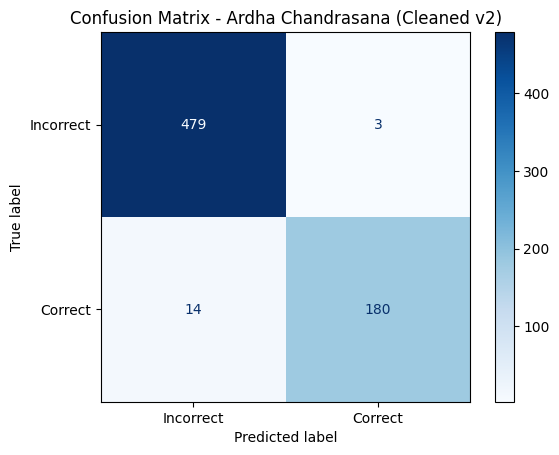

In [32]:
cm_v2 = confusion_matrix(y_test_v2, test_pred_v2)

disp_v2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=["Incorrect", "Correct"]
)

disp_v2.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME} (Cleaned v2)")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower().replace(' ', '_')}_cleaned_v2.png", dpi=150, bbox_inches="tight")
plt.show()

### Feature Importance (v2)

          Feature  Importance
0      right_knee    0.191620
1        left_hip    0.181327
2  right_shoulder    0.176167
3   left_shoulder    0.175301
4       right_hip    0.152745
5       left_knee    0.122840


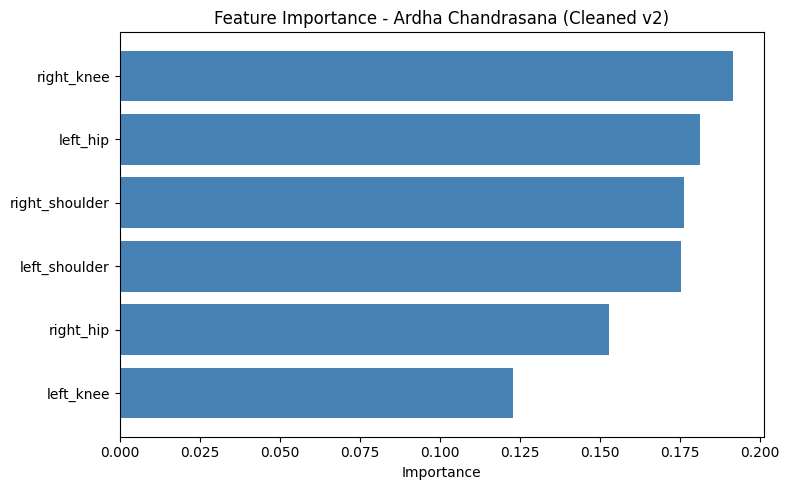

In [33]:
importance_df_v2 = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_v2.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df_v2)

plt.figure(figsize=(8, 5))
plt.barh(importance_df_v2["Feature"], importance_df_v2["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME} (Cleaned v2)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower().replace(' ', '_')}_cleaned_v2.png", dpi=150)
plt.show()

### Confidence (v2)

Average confidence : 95.82%
Minimum confidence : 51.00%


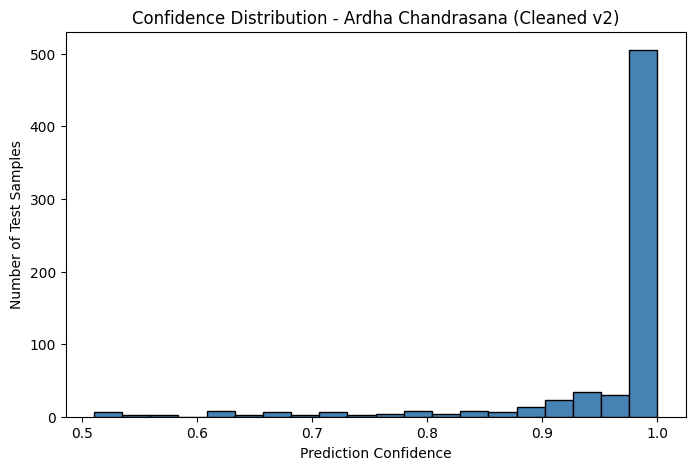

In [34]:
test_probs_v2 = rf_v2.predict_proba(X_test_v2)
test_confidence_v2 = test_probs_v2.max(axis=1)

print(f"Average confidence : {test_confidence_v2.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence_v2.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence_v2, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME} (Cleaned v2)")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower().replace(' ', '_')}_cleaned_v2.png", dpi=150)
plt.show()

### Save Final Model and Metadata (v2)
**This overwrites `ardha_chandrasana_rf.pkl` / `ardha_chandrasana_rf_metadata.json` with the v2 model. This supersedes v1 and is the final Ardha Chandrasana model going forward.**

In [35]:
joblib.dump(rf_v2, MODEL_FILENAME)

metadata_v2 = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy_v2, 4),
    "val_accuracy": round(val_accuracy_v2, 4),
    "test_accuracy": round(test_accuracy_v2, 4),
    "test_precision": round(test_precision_v2, 4),
    "test_recall": round(test_recall_v2, 4),
    "test_f1_score": round(test_f1_v2, 4),
    "n_estimators": rf_v2.n_estimators,
    "random_state": rf_v2.random_state,
    "data_cleaned": True,
    "fix_version": 2,
    "note": f"v2: Removed {removed_count_v2} straight-hip/knee rows ({removed_count_v2/len(raw_correct_v2)*100:.1f}%) mislabeled as Correct, regardless of arm position. Added {N_SYNTHETIC_V2} synthetic examples spanning the FULL shoulder range (0-180 deg). Fixes v1 gap where standing-with-arms-raised was still misclassified as Correct."
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata_v2, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")
print("This is the final Ardha Chandrasana model (v2) - handles arms-raised standing correctly.")

Model saved as ardha_chandrasana_rf.pkl
Metadata saved as ardha_chandrasana_rf_metadata.json
This is the final Ardha Chandrasana model (v2) - handles arms-raised standing correctly.
